In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

# ---- units ----------------------------------------------------------------
# Losses are multiplied by LOSS_SCALE when the distributions are built.
#   1.0  -> dollars (default, easiest to read)
#   1e-6 -> $m,   1e-9 -> $bn
LOSS_SCALE = 1.0
# The variance penalty has units of 1/(loss unit), so gamma depends on LOSS_SCALE.
# Gammas below are written "per $bn"; multiply by PER_BN to convert to the current units.
PER_BN = 1e-9 / LOSS_SCALE


In [2]:
all_agg_annual_losses = pd.read_csv("results/annual_losses_v2.csv")

# models = ['IRIS', 'STORM', 'CHAZ', 'IBTrACS_p', 'MINI-WNC-QM', 'IBTrACS', 'MINI-WNC']
models = ['IRIS', 'STORM', 'CHAZ']

tc_losses = {}
for model in models:
    df_sub = all_agg_annual_losses[all_agg_annual_losses['model'] == model].copy()
    df_sub['frequency'] = 1 / len(df_sub)
    tc_losses[model] = df_sub


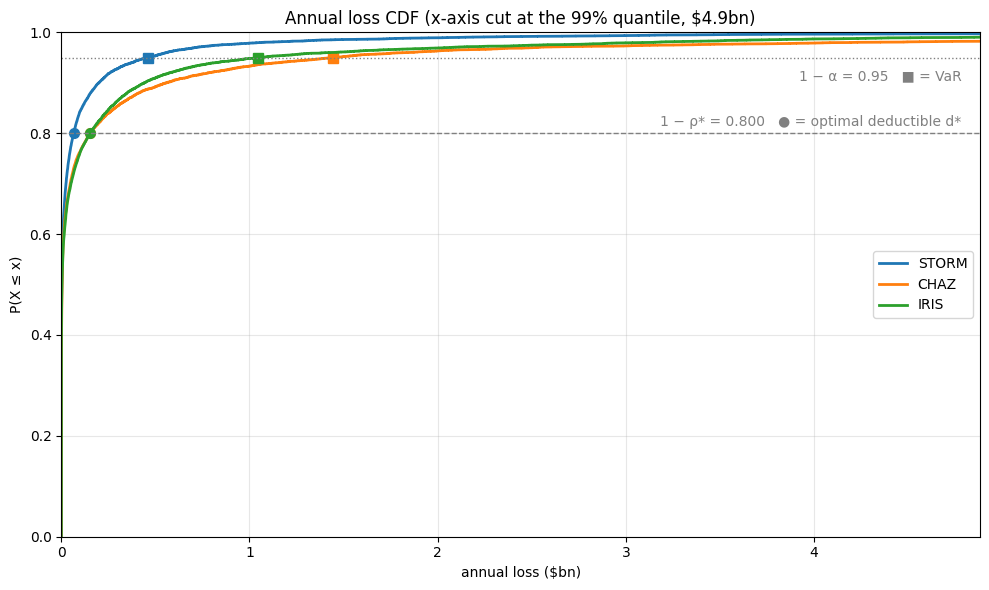

In [3]:
plot_models = ["STORM", "CHAZ", "IRIS"]
loading, alpha = 4, 0.05
rho_star = 1 / (1 + loading)
x_max_quantile = 0.99        # x-axis stops at this quantile of the pooled losses (the tail is very long)

fig, ax = plt.subplots(figsize=(10, 6))

pooled = np.concatenate([tc_losses[m]["loss"].to_numpy() for m in plot_models])
x_max = np.quantile(pooled, x_max_quantile) / 1e9

for m in plot_models:
    x = np.sort(tc_losses[m]["loss"].to_numpy()) / 1e9          # $bn
    n = len(x)
    F = np.arange(1, n + 1) / n                                  # empirical CDF, P(X <= x)
    line, = ax.step(np.concatenate([[0.0], x]), np.concatenate([[0.0], F]),
                    where="post", lw=2, label=m)

    # optimal deductible d* (where F = 1 - rho*) and VaR (where F = 1 - alpha)
    d_star = x[np.searchsorted(F, 1 - rho_star - 1e-12)]
    var_a  = x[np.searchsorted(F, 1 - alpha - 1e-12)]
    ax.plot(d_star, 1 - rho_star, "o", color=line.get_color(), ms=7)
    ax.plot(var_a, 1 - alpha, "s", color=line.get_color(), ms=7)

ax.axhline(1 - rho_star, color="grey", ls="--", lw=1)
ax.axhline(1 - alpha, color="grey", ls=":", lw=1)
ax.text(0.98, 1 - rho_star + 0.015, f"1 − ρ* = {1 - rho_star:.3f}   ● = optimal deductible d*",
        transform=ax.get_yaxis_transform(), ha="right", color="grey")
ax.text(0.98, 1 - alpha - 0.045, f"1 − α = {1 - alpha:.2f}   ■ = VaR",
        transform=ax.get_yaxis_transform(), ha="right", color="grey")

ax.set_xlim(0, x_max)
ax.set_ylim(0, 1)
ax.set_xlabel("annual loss ($bn)")
ax.set_ylabel("P(X ≤ x)")
ax.set_title(f"Annual loss CDF (x-axis cut at the {x_max_quantile:.0%} quantile, ${x_max:.1f}bn)")
ax.legend(loc="center right")
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()


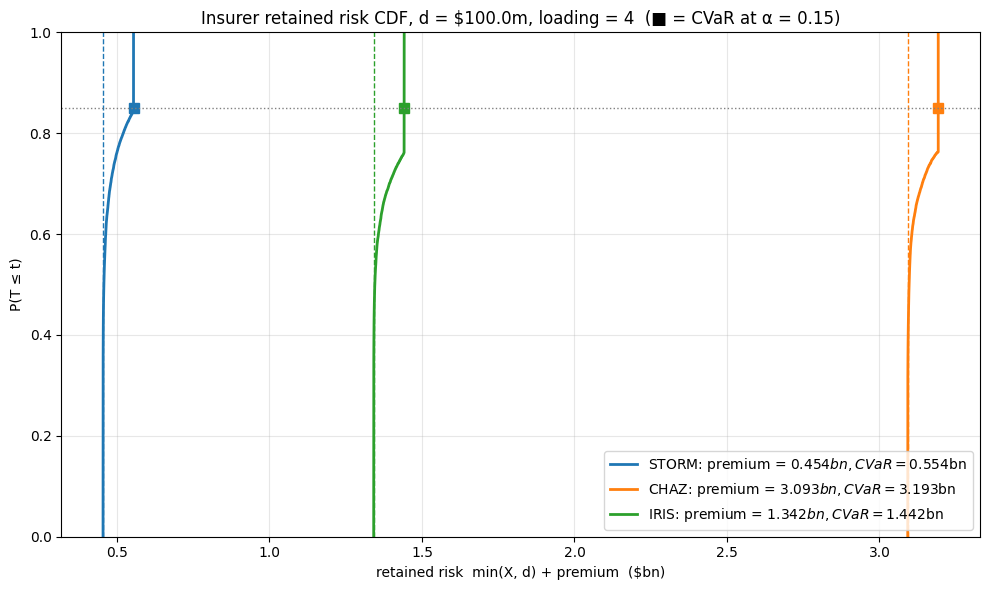

In [4]:
plot_models = ["STORM", "CHAZ", "IRIS"]
loading, alpha = 4, 0.15
d = 1e8                      # deductible ($) - change this

fig, ax = plt.subplots(figsize=(10, 6))
t_min, t_max = np.inf, -np.inf

for m in plot_models:
    x = tc_losses[m]["loss"].to_numpy()
    premium = (1 + loading) * np.mean(np.maximum(x - d, 0.0))   # EV principle, model's own premium
    T = np.sort(np.minimum(x, d) + premium) / 1e9               # total retained risk, $bn
    n = len(T)
    F = np.arange(1, n + 1) / n                                  # empirical CDF, P(T <= t)

    # CVaR_alpha of T (upper tail, same definition as calc_CVaR)
    var_T = T[np.searchsorted(F, 1 - alpha - 1e-12)]
    cvar_T = var_T + np.mean(np.maximum(T - var_T, 0.0)) / alpha

    line, = ax.step(np.concatenate([[T[0]], T]), np.concatenate([[0.0], F]), where="post", lw=2,
                    label=f"{m}: premium = ${premium/1e9:.3f}bn, CVaR = ${cvar_T:.3f}bn")
    ax.axvline(premium / 1e9, color=line.get_color(), ls="--", lw=1)      # T can't be below the premium
    ax.plot(cvar_T, 1 - alpha, "s", color=line.get_color(), ms=7)
    t_min, t_max = min(t_min, T[0]), max(t_max, T[-1])

pad = 0.05 * (t_max - t_min)
ax.axhline(1 - alpha, color="grey", ls=":", lw=1)
ax.set_xlim(max(0.0, t_min - pad), t_max + pad)
ax.set_ylim(0, 1)
ax.set_xlabel("retained risk  min(X, d) + premium  ($bn)")
ax.set_ylabel("P(T ≤ t)")
ax.set_title(f"Insurer retained risk CDF, d = ${d/1e6:,.1f}m, loading = {loading}  (■ = CVaR at α = {alpha})")
ax.legend(loc="lower right")
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()


In [5]:
from collections import namedtuple
LossDist = namedtuple('LossDist', ['xk', 'pk'])

def create_rv_discrete(tc_annual_loss_freq_table, scale=None):
    scale = LOSS_SCALE if scale is None else scale
    aggregated = (
        tc_annual_loss_freq_table
        .groupby('loss', as_index=False)['frequency']
        .sum()
        .sort_values('loss')
    )
    xk = aggregated['loss'].to_numpy() * scale
    pk = aggregated['frequency'].to_numpy()
    return LossDist(xk, pk / pk.sum())

def calc_VaR(rv, alpha, tol=1e-12):
    order = np.argsort(rv.xk)
    x, p = rv.xk[order], rv.pk[order]
    cdf = np.cumsum(p)
    idx = np.searchsorted(cdf, (1.0 - alpha) - tol, side='left')
    return float(x[min(idx, len(x) - 1)])


def calc_CVaR(rv, alpha):
    var_val = calc_VaR(rv, alpha)
    excess = np.maximum(rv.xk - var_val, 0.0)
    return float(var_val + np.sum(excess * rv.pk) / alpha)


def get_TC_model_array(models, tc_dict=tc_losses):
    """
    Takes a list of model name strings and a dictionary of model DataFrames,
    returning a list of scipy.stats.rv_discrete objects in the specified order.
    """
    rv_array = []
    for model in models:
        if model not in tc_dict:
            raise KeyError(f"Model '{model}' not found in provided dictionary.")
        
        df = tc_dict[model]
        rv_obj = create_rv_discrete(df)
        rv_array.append(rv_obj)
        
    return rv_array


In [6]:
PREMIUM_PRINCIPLE = 'ev'    # 'ev' or 'ph'
PH_C = 0.7                  # PH-transform index c in (0, 1]; only used when PREMIUM_PRINCIPLE == 'ph' (c = 1 gives 'ev')

def ph_layer_integral(rv, deductible: float, c: float):
    """
    int_d^inf S(x)^c dx for a discrete loss distribution (S is a step function).
    With c = 1 this equals E[(X - d)+].
    """
    order = np.argsort(rv.xk)
    x, p = rv.xk[order], rv.pk[order]
    S = np.clip(1.0 - np.cumsum(p), 0.0, 1.0)          # S(x) on [x_k, x_{k+1})
    left = np.concatenate([[0.0], x[:-1]])              # intervals [0, x_0), [x_0, x_1), ...
    right = x
    S_int = np.concatenate([[1.0], S[:-1]])             # S = 1 below the smallest loss
    width = np.clip(right - np.maximum(left, deductible), 0.0, None)
    return float(np.sum(width * S_int ** c))

def calc_stop_loss_premium(rv, deductible: float, loading: float):
    """
    'ev': (1 + loading) * E[(X-d)+]
    'ph': (1 + loading) * int_d^inf S(x)^c dx   (Wang 1995 PH transform, c = PH_C)
    """
    if PREMIUM_PRINCIPLE == 'ph':
        return float((1 + loading) * ph_layer_integral(rv, deductible, PH_C))

    if PREMIUM_PRINCIPLE == 'ev':
        return float((1 + loading) * np.sum(np.maximum(0.0, rv.xk - deductible) * rv.pk))

    raise ValueError(f"Unknown principle: {PREMIUM_PRINCIPLE}")

def total_insurer_loss(rv, loss, deductible, loading):
    retained = np.minimum(loss, deductible)
    return (retained + calc_stop_loss_premium(rv, deductible, loading))

def delta(rv_array, model_i, d, loading):
    premiums = [calc_stop_loss_premium(rv, d, loading) for rv in rv_array]
    return (premiums[model_i] - np.mean(premiums))


In [ ]:
def single_model_total_risk_cvar(rv, d, loading, alpha):
    d = max(0.0, float(d))
    premium = calc_stop_loss_premium(rv, d, loading)
    total = LossDist(np.minimum(rv.xk, d) + premium, rv.pk)
    return calc_CVaR(total, alpha)

def mixture_cvar(rv_array, weights, d, loading, alpha):
    """CVaR_alpha of the mixture of per-model total-risk distributions."""
    weights = np.asarray(weights, dtype=float)
    d = max(0.0, float(d))

    mixed = LossDist(
        np.concatenate([rv.xk for rv in rv_array]),
        np.concatenate([w * rv.pk for rv, w in zip(rv_array, weights)])
    )
    premium = calc_stop_loss_premium(mixed, d, loading)
    total = LossDist(np.minimum(mixed.xk, d) + premium, mixed.pk)
    return calc_CVaR(total, alpha)


def blend_and_variance_cvar(rv_array, weights, d, loading, alpha):
    """CVaR of the blend (priced on the blend), plus variance of the per-model CVaRs."""
    weights = np.asarray(weights, dtype=float)
    cvars = np.array([
        single_model_total_risk_cvar(rv, d, loading, alpha) for rv in rv_array
    ])
    mix_c = mixture_cvar(rv_array, weights, d, loading, alpha)    
    var_c = np.sum(weights * (cvars - np.sum(weights * cvars)) ** 2)
    return mix_c, var_c, cvars

# ---- deductible grid + minimize_scalar refinement ----
def make_grid(rv_array, weights, loading, alpha, n=400, min_frac=1e-8):
    """Coarse log-spaced deductible grid with (blend CVaR, variance CVaR) at each point."""
    dmax = float(max(rv.xk.max() for rv in rv_array))
    d_grid = np.concatenate([[0.0], np.geomspace(min_frac * dmax, dmax, n)])
    vals = np.array([
        blend_and_variance_cvar(rv_array, weights, d, loading, alpha)[:2]
        for d in d_grid
    ])
    return d_grid, vals

def optimize_deductible_mean_variance(rv_array, weights, loading, alpha, gamma, grid=None):
    """
    Solves: min_d mean_CVaR(d) + gamma * variance_CVaR(d).

    Returns the optimal deductible only if all effective weights
    are non-negative:
        1 + 2 * gamma * delta_i(d*) >= 0 for every model.
    """
    max_possible_loss = float(max(np.max(rv.xk) for rv in rv_array))

    def objective(d):
        blend_c, var_c, _ = blend_and_variance_cvar(
            rv_array, weights, d, loading, alpha
        )
        return blend_c + gamma * var_c

    if grid is None:
        grid = make_grid(rv_array, weights, loading, alpha)
    d_grid, vals = grid

    i = int(np.argmin(vals[:, 0] + gamma * vals[:, 1]))
    lo = d_grid[max(i - 1, 0)]
    hi = d_grid[min(i + 1, len(d_grid) - 1)]

    opt_result = minimize_scalar(
        objective,
        bounds=(lo, hi),
        method='bounded'
    )

    d_star = float(opt_result.x)

    # keep the grid point if the refinement is somehow worse
    if objective(d_star) > vals[i, 0] + gamma * vals[i, 1]:
        d_star = float(d_grid[i])
    blend_star, var_star, cvars_star = blend_and_variance_cvar(
        rv_array, weights, d_star, loading, alpha
    )

    premiums = np.array([
        calc_stop_loss_premium(rv, d_star, loading)
        for rv in rv_array
    ])
    delta = premiums - np.sum(np.asarray(weights) * premiums)

    # Check effective-weight non-negativity for every model
    effective_weight_factors = 1 + 2 * gamma * delta
    valid_weights = np.all(effective_weight_factors >= -1e-10)

    if not valid_weights:
        return None

    return {
        'gamma': gamma,
        'optimal_deductible': d_star,
        'blend_CVaR': blend_star,
        'variance_CVaR': var_star,
        'per_model_CVaR': cvars_star,
        'effective_weight_factors': effective_weight_factors,
        'effective_weights': np.asarray(weights) * effective_weight_factors,
    }


def find_max_gamma(rv_array, weights, loading, alpha, grid=None, rtol=1e-3, max_doublings=60, verbose=True):
    """
    Largest gamma for which the optimal deductible still gives non-negative effective weights
    w_i (1 + 2 gamma delta_i(d*)) for every model, i.e. the end of the valid frontier.

    1. Start from the closed-form cap at the gamma = 0 optimum: gamma_0 = min over delta_i < 0 of -1/(2 delta_i).
    2. If gamma_0 is still valid (delta changes with d along the frontier), double it until it is not.
    3. Bisect between the last valid and first invalid gamma until they agree to rtol.
    Assumes validity is lost only once as gamma grows (true when the most optimistic model's
    effective weight keeps falling), which is the usual case.
    """
    w = np.asarray(weights, dtype=float)
    if grid is None:
        grid = make_grid(rv_array, w, loading, alpha)

    def valid(g):
        return optimize_deductible_mean_variance(rv_array, w, loading, alpha, g, grid=grid) is not None

    base = optimize_deductible_mean_variance(rv_array, w, loading, alpha, 0.0, grid=grid)
    d0 = base["optimal_deductible"]
    P = np.array([calc_stop_loss_premium(rv, d0, loading) for rv in rv_array])
    dl = P - np.sum(w * P)
    if not np.any(dl < 0):
        if verbose:
            print("all models give the same premium at d*: no variance trade-off (max gamma = 0)")
        return 0.0
    g0 = float(np.min(-1 / (2 * dl[dl < 0])))

    lo, hi = 0.0, g0
    for _ in range(max_doublings):
        if not valid(hi):
            break
        lo, hi = hi, 2 * hi
    else:
        if verbose:
            print(f"warning: still valid after {max_doublings} doublings; returning gamma = {lo:.3e}")
        return lo

    while (hi - lo) > rtol * hi:
        mid = 0.5 * (lo + hi)
        if valid(mid):
            lo = mid
        else:
            hi = mid

    if verbose:
        end = optimize_deductible_mean_variance(rv_array, w, loading, alpha, lo, grid=grid)
        k = int(np.argmin(end["effective_weights"]))
        print(f"max gamma = {lo:.4e} ({lo / PER_BN:.4f} per $bn; closed-form cap at gamma = 0: {g0 / PER_BN:.4f} per $bn); "
              f"lowest effective weight there: model {k} = {end['effective_weights'][k]:.4f}")
    return lo


def generate_mean_variance_frontier(
    rv_array, weights, loading, alpha, max_gamma=None, n_points=25
):
    """
    Sweeps gamma from 0 to max_gamma and keeps only records with valid effective weights.
    max_gamma=None (default) finds the end of the valid frontier automatically (find_max_gamma),
    so the sweep covers the full frontier.
    """
    grid = make_grid(rv_array, weights, loading, alpha)
    if max_gamma is None:
        max_gamma = find_max_gamma(rv_array, weights, loading, alpha, grid=grid)
    gamma_vec = np.linspace(0, max_gamma, n_points)

    records = [
        optimize_deductible_mean_variance(
            rv_array, weights, loading, alpha, gamma, grid=grid
        )
        for gamma in gamma_vec
    ]

    records = [record for record in records if record is not None]

    return pd.DataFrame(records)

def plot_frontier(frontier_df, pct=False, title="Mean–Variance CVaR Frontier"):
    """
    pct = False   : absolute values
    pct = True    : % change relative to the gamma = 0 point
    pct = "both"  : absolute (top) and % change (bottom) in one figure
    """
    frontier_df = frontier_df.sort_values("gamma")
    base = frontier_df.iloc[0]              # gamma = 0 row (smallest gamma)

    def draw(ax, use_pct):
        x = frontier_df["variance_CVaR"]
        y = frontier_df["blend_CVaR"]

        if use_pct:
            x = 100 * (x / base["variance_CVaR"] - 1)
            y = 100 * (y / base["blend_CVaR"] - 1)
            xlabel = "% change in variance of CVaR (vs gamma = 0)"
            ylabel = "% change in blend CVaR (vs gamma = 0)"
        else:
            xlabel = "Variance of CVaR"
            ylabel = "Blend CVaR"

        ax.plot(x, y, marker="o", markersize=4)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(True, alpha=0.3)

    if pct == "both":
        fig, axes = plt.subplots(2, 1, figsize=(9, 11))
        draw(axes[0], use_pct=False)
        draw(axes[1], use_pct=True)
        axes[0].set_title("Absolute values")
        axes[1].set_title("% change vs gamma = 0")
        fig.suptitle(title)
    else:
        fig, ax = plt.subplots(figsize=(9, 6))
        draw(ax, use_pct=bool(pct))
        ax.set_title(title)

    fig.tight_layout()
    plt.show()


In [8]:
def closed_form_deductible(rv_array, wts, loading, adj=None):
    """
    Closed-form deductible (valid for d below every model's VaR) for the objective
        CVaR_alpha(blend total risk) + gamma * variance of per-model CVaRs,
    whose first-order condition is

        S_blend(d)^c + sum_i w_i * adj_i * S_i(d)^c = 1/(1+loading),
        S_blend = sum_i w_i S_i,   adj_i = 2*gamma*delta_i,   delta_i = pi_i - sum_j w_j pi_j,
        c = 1 for 'ev', c = PH_C for 'ph'.

    'ev' (c = 1): reduces to sum_i w_i (1 + adj_i) S_i(d) = 1/(1+loading)  (reweighted Cai & Tan).
    gamma = 0  : reduces to S_blend(d)^c = 1/(1+loading)  (single-model result on the blend).
    Returns the smallest loss value d at which the left-hand side is <= 1/(1+loading).
    """
    if PREMIUM_PRINCIPLE == 'ev':
        c = 1.0
    elif PREMIUM_PRINCIPLE == 'ph':
        c = PH_C
    else:
        raise ValueError("closed form only derived for 'ev' and 'ph'")
    target = 1.0 / (1.0 + loading)
    wts = np.asarray(wts, dtype=float)
    adj = np.zeros(len(rv_array)) if adj is None else np.asarray(adj, dtype=float)
    cand = np.unique(np.concatenate([[0.0]] + [rv.xk for rv in rv_array]))
    S_blend = np.zeros_like(cand)
    pen = np.zeros_like(cand)
    for rv, wi, ai in zip(rv_array, wts, adj):
        order = np.argsort(rv.xk)
        x, cdf = rv.xk[order], np.cumsum(rv.pk[order])
        k = np.searchsorted(x, cand, side='right') - 1          # P(X <= d) = cdf[k]
        S = np.clip(np.where(k >= 0, 1.0 - cdf[np.clip(k, 0, None)], 1.0), 0.0, 1.0)
        S_blend += wi * S
        pen += wi * ai * S ** c
    h = S_blend ** c + pen
    below = np.nonzero(h <= target + 1e-12)[0]
    return float(cand[below[0]] if len(below) else cand[-1])


def closed_form_deductible_check(frontier_df, rv_array, weights, loading, alpha,
                                 max_iter=100, rtol=1e-12):
    """
    For each gamma in the frontier, solve the first-order condition (see closed_form_deductible)
        S_blend(d*)^c + 2*gamma * sum_i w_i delta_i S_i(d*)^c = 1/(1+loading)
    and compare with the numerical optimum. For 'ev' this is the effective-weight blend
    sum_i w_i (1 + 2*gamma*delta_i) S_i(d*) = 1/(1+loading).

    d_closed_form : uses 2*gamma*delta_i stored in the frontier (taken at the numerical d*)
    d_fixed_point : iterates d -> closed_form_deductible(2*gamma*delta(d)) until it stops changing
                    (delta depends on d through the premiums)
    beats_no_reinsurance : objective at d_fixed_point < objective with no reinsurance
                    (needed under 'ph': the objective falls back towards the no-reinsurance
                     value deep in the tail, so the FOC point is only a local optimum)
    """
    w = np.asarray(weights, dtype=float)
    min_var = min(calc_VaR(rv, alpha) for rv in rv_array)   # closed form needs d* below every model's VaR
    d_none = float(max(rv.xk.max() for rv in rv_array))      # deductible = max loss  <=> no reinsurance

    def adj(d, gamma):
        P = np.array([calc_stop_loss_premium(rv, d, loading) for rv in rv_array])
        return 2 * gamma * (P - np.sum(w * P))

    def objective(d, gamma):
        b, v, _ = blend_and_variance_cvar(rv_array, w, d, loading, alpha)
        return b + gamma * v

    rows = []
    for _, r in frontier_df.iterrows():
        g, d_num = r["gamma"], r["optimal_deductible"]

        d_cf = closed_form_deductible(rv_array, w, loading,
                                      adj=np.asarray(r["effective_weight_factors"], dtype=float) - 1)

        d_fp = d_cf
        for _ in range(max_iter):
            d_new = closed_form_deductible(rv_array, w, loading, adj=adj(d_fp, g))
            converged = abs(d_new - d_fp) <= rtol * max(abs(d_fp), 1e-300)
            d_fp = d_new
            if converged:
                break

        obj_num, obj_fp, obj_none = objective(d_num, g), objective(d_fp, g), objective(d_none, g)
        rows.append({
            "gamma": g,
            "d_numerical": d_num,
            "d_closed_form": d_cf,
            "d_fixed_point": d_fp,
            "rel_diff_closed_form": (d_cf - d_num) / d_num,
            "rel_diff_fixed_point": (d_fp - d_num) / d_num,
            "objective_numerical": obj_num,
            "objective_fixed_point": obj_fp,
            "objective_no_reinsurance": obj_none,
            "closed_form_not_worse": obj_fp <= obj_num * (1 + 1e-12),
            "beats_no_reinsurance": obj_fp < obj_none,
            "d_below_all_VaR": d_fp < min_var,
        })

    out = pd.DataFrame(rows)
    print(f"max |rel diff| closed form vs numerical: {out['rel_diff_closed_form'].abs().max():.2e}")
    print(f"max |rel diff| fixed point vs numerical: {out['rel_diff_fixed_point'].abs().max():.2e}")
    print(f"closed form objective <= numerical objective in {out['closed_form_not_worse'].sum()} "
          f"of {len(out)} rows;  d below every model's VaR in all rows: {out['d_below_all_VaR'].all()};  "
          f"beats no reinsurance in all rows: {out['beats_no_reinsurance'].all()}")
    return out


In [9]:
alpha = 0.05
names = ["STORM", "CHAZ", "IRIS"]
rv_array = get_TC_model_array(names, tc_losses)
w = np.array([1/3, 1/3, 1/3])

k = names.index("CHAZ")
tail_level = alpha / w[k]                        # 0.15 -> CHAZ's 85th percentile
chaz_q = calc_VaR(rv_array[k], tail_level)       # your calc_VaR takes the tail probability

print(f"CHAZ {1 - tail_level:.2%} percentile: {chaz_q:,.0f}")
for name, rv in zip(names, rv_array):
    if name != "CHAZ":
        print(f"max {name}: {rv.xk.max():,.0f}  (below CHAZ quantile: {rv.xk.max() < chaz_q})")

# direct check: where does the mixture's worst-alpha mass come from?
mixed = LossDist(np.concatenate([rv.xk for rv in rv_array]),
                 np.concatenate([wi * rv.pk for rv, wi in zip(rv_array, w)]))
var_mix = calc_VaR(mixed, alpha)
print("\nMixture VaR:", f"{var_mix:,.0f}")
for name, rv, wi in zip(names, rv_array, w):
    print(f"{name}: mass above mixture VaR = {wi * rv.pk[rv.xk > var_mix].sum():.4f}")


CHAZ 85.00% percentile: 285,904,293
max STORM: 32,817,913,816  (below CHAZ quantile: False)
max IRIS: 57,787,549,865  (below CHAZ quantile: False)

Mixture VaR: 922,455,874
STORM: mass above mixture VaR = 0.0077
CHAZ: mass above mixture VaR = 0.0237
IRIS: mass above mixture VaR = 0.0186


In [10]:
# Solve the unpenalised problem
PREMIUM_PRINCIPLE = 'ev'  
rv_array = get_TC_model_array(["STORM", "IRIS"], tc_losses)
weights = np.array([1/2, 1/2])

base = optimize_deductible_mean_variance(
    rv_array, weights, loading=4, alpha=0.05, gamma=0
)

d0 = base["optimal_deductible"]

# Calculate premium differences at the baseline deductible
premiums = np.array([
    calc_stop_loss_premium(rv, d0, 0.3)
    for rv in rv_array
])

delta = premiums - np.sum(weights * premiums)

# Initial estimate of the maximum admissible gamma
negative_delta = delta[delta < 0]

gamma_cap = (
    np.min(-1 / (2 * negative_delta))
    if len(negative_delta) else np.inf
)

print("Baseline deductible:", d0)
print("Premium differences:", delta)
print("Initial gamma cap:", gamma_cap)


Baseline deductible: 97468852.3057295
Premium differences: [-1.15505369e+08  1.15505369e+08]
Initial gamma cap: 4.328803105443747e-09


max gamma = 4.3045e-10 (0.4304 per $bn; closed-form cap at gamma = 0: 0.4267 per $bn); lowest effective weight there: model 0 = 0.0002


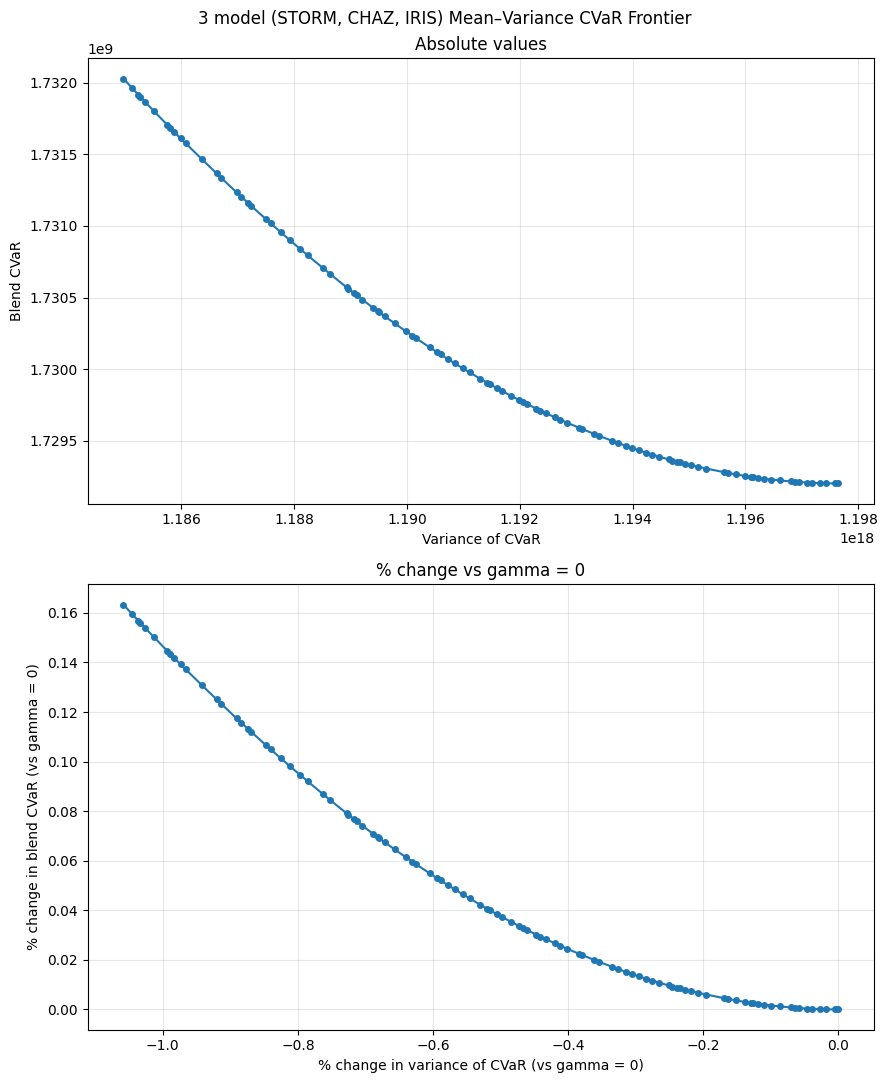

In [23]:
rv_array = get_TC_model_array(["STORM", "CHAZ", "IRIS"], tc_losses)
weights = np.array([1/3, 1/3, 1/3])

PREMIUM_PRINCIPLE = 'ev'  
ev_frontier_df = generate_mean_variance_frontier(rv_array, weights, loading=4, alpha=0.05, n_points=100)
plot_frontier(ev_frontier_df, pct="both", title="3 model (STORM, CHAZ, IRIS) Mean–Variance CVaR Frontier")


In [24]:
cf_check = closed_form_deductible_check(ev_frontier_df, rv_array, weights, loading=4, alpha=0.05)
cf_check


max |rel diff| closed form vs numerical: 6.84e-04
max |rel diff| fixed point vs numerical: 6.84e-04
closed form objective <= numerical objective in 99 of 100 rows;  d below every model's VaR in all rows: True;  beats no reinsurance in all rows: True


,gamma,d_numerical,d_closed_form,d_fixed_point,rel_diff_closed_form,rel_diff_fixed_point,objective_numerical,objective_fixed_point,objective_no_reinsurance,closed_form_not_worse,beats_no_reinsurance,d_below_all_VaR
0,0.000000e+00,1.133227e+08,1.133227e+08,1.133227e+08,4.005455e-10,4.005455e-10,1.729203e+09,1.729203e+09,5.902583e+09,True,True,True
1,4.347959e-12,1.134922e+08,1.134922e+08,1.134922e+08,-6.701744e-09,-6.701744e-09,1.734411e+09,1.734411e+09,5.972386e+09,True,True,True
2,8.695917e-12,1.140142e+08,1.140142e+08,1.140142e+08,1.121126e-09,1.121126e-09,1.739617e+09,1.739617e+09,6.042188e+09,True,True,True
3,1.304388e-11,1.143650e+08,1.143650e+08,1.143650e+08,4.541845e-09,4.541845e-09,1.744823e+09,1.744823e+09,6.111991e+09,True,True,True
4,1.739183e-11,1.148442e+08,1.148442e+08,1.148442e+08,8.779072e-09,8.779072e-09,1.750029e+09,1.750029e+09,6.181794e+09,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...
95,4.130561e-10,1.533372e+08,1.533372e+08,1.533372e+08,-1.505809e-09,-1.505809e-09,2.221484e+09,2.221484e+09,1.253383e+10,True,True,True
96,4.174040e-10,1.536084e+08,1.536084e+08,1.536084e+08,6.529949e-09,6.529949e-09,2.226638e+09,2.226638e+09,1.260363e+10,True,True,True
97,4.217520e-10,1.537295e+08,1.537295e+08,1.537295e+08,-1.304283e-08,-1.304283e-08,2.231792e+09,2.231792e+09,1.267343e+10,True,True,True
98,4.261000e-10,1.541074e+08,1.541074e+08,1.541074e+08,1.192734e-09,1.192734e-09,2.236945e+09,2.236945e+09,1.274324e+10,True,True,True


In [13]:
ev_frontier_df


,gamma,optimal_deductible,blend_CVaR,variance_CVaR,per_model_CVaR,effective_weight_factors,effective_weights
0,0.000000e+00,1.133227e+08,1.729203e+09,1.197649e+18,"[557413412.6649055, 3190686342.642582, 1439510...","[1.0, 1.0, 1.0]","[0.3333333333333333, 0.3333333333333333, 0.333..."
1,4.347959e-12,1.134922e+08,1.729203e+09,1.197597e+18,"[557458409.0236123, 3190664360.1477056, 143948...","[0.9898106016614474, 1.0127087431943331, 0.997...","[0.32993686722048243, 0.3375695810647777, 0.33..."
2,8.695917e-12,1.140142e+08,1.729204e+09,1.197436e+18,"[557597544.3377824, 3190597376.195919, 1439418...","[0.9796236071903084, 1.0254163054638439, 0.994...","[0.3265412023967694, 0.3418054351546146, 0.331..."
3,1.304388e-11,1.143650e+08,1.729206e+09,1.197328e+18,"[557692241.7146305, 3190552850.6722126, 143937...","[0.9694378481903906, 1.03812326358815, 0.99243...","[0.32314594939679686, 0.3460410878627167, 0.33..."
4,1.739183e-11,1.148442e+08,1.729208e+09,1.197180e+18,"[557821887.1960171, 3190492931.249925, 1439309...","[0.9592548936132571, 1.050828853713935, 0.9899...","[0.319751631204419, 0.35027628457131166, 0.329..."
...,...,...,...,...,...,...,...
95,4.130561e-10,1.533372e+08,1.731865e+09,1.185359e+18,"[570654574.6213242, 3188102003.840537, 1436837...","[0.040710298860778815, 2.2030154379778137, 0.7...","[0.013570099620259604, 0.7343384793259379, 0.2..."
96,4.174040e-10,1.536084e+08,1.731899e+09,1.185275e+18,"[570761271.3774253, 3188100579.436136, 1436836...","[0.030672511581316897, 2.215648497008197, 0.75...","[0.010224170527105631, 0.7385494990027324, 0.2..."
97,4.217520e-10,1.537295e+08,1.731915e+09,1.185238e+18,"[570808941.6140356, 3188100095.2005444, 143683...","[0.020602365817032786, 2.2282978992692932, 0.7...","[0.0068674552723442615, 0.7427659664230977, 0...."
98,4.261000e-10,1.541074e+08,1.731965e+09,1.185121e+18,"[570958619.6544911, 3188099096.6558394, 143683...","[0.010590834486406964, 2.2409177091341523, 0.7...","[0.0035302781621356543, 0.746972569711384, 0.2..."


## PH-transform premium (Wang 1995)

Premium $\pi(d) = (1+\theta)\int_d^\infty S(x)^c\,dx$. The objective is unchanged: CVaR of the blend (priced on the blend) $+\ \gamma\,\times$ variance of the per-model CVaRs (each priced on its own model).
For $d$ below every model's VaR the first-order condition is
$S_{\text{blend}}(d)^c + 2\gamma\sum_i w_i\,\delta_i(d)\,S_i(d)^c = 1/(1+\theta)$, with $\delta_i = \pi_i - \sum_j w_j\pi_j$.
At $\gamma = 0$ this is $S_{\text{blend}}(d^*) = (1+\theta)^{-1/c}$; with $c = 1$ it is the effective-weight result.

all models give the same premium at d*: no variance trade-off (max gamma = 0)


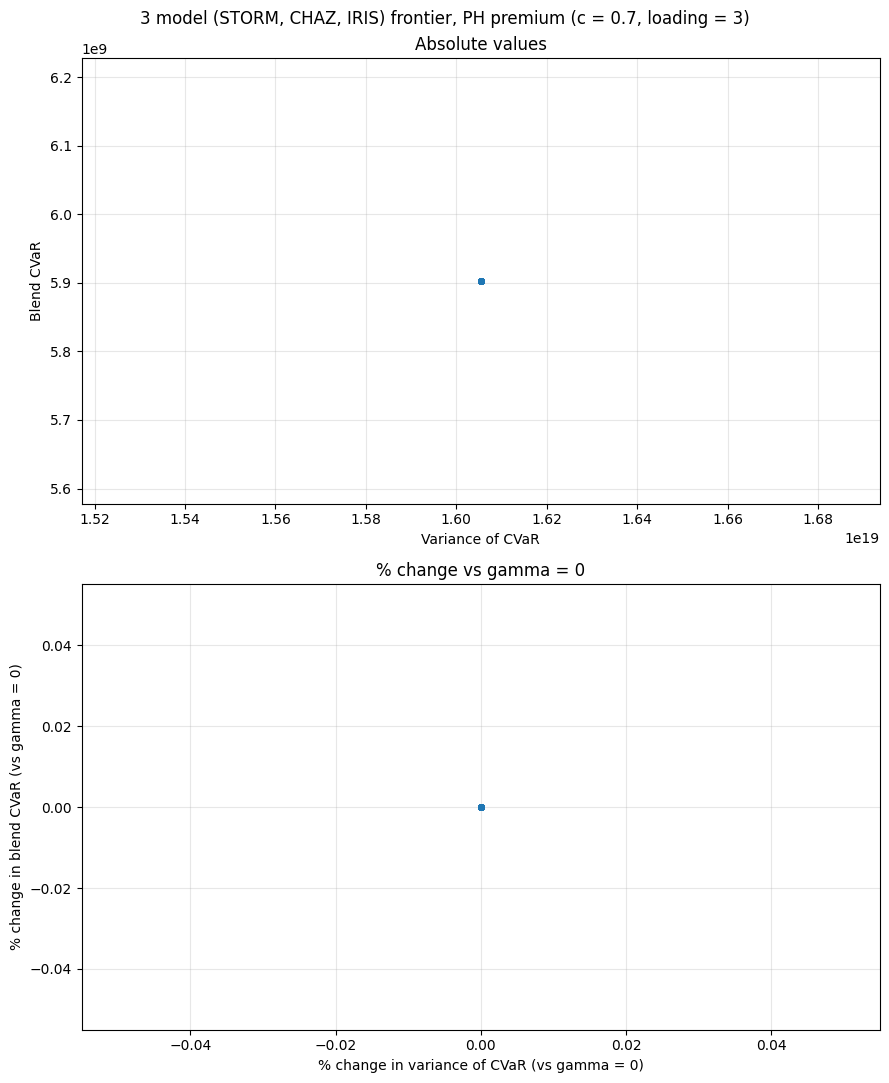

max |rel diff| closed form vs numerical: 9.99e-01
max |rel diff| fixed point vs numerical: 9.99e-01
closed form objective <= numerical objective in 0 of 100 rows;  d below every model's VaR in all rows: True;  beats no reinsurance in all rows: False


,gamma,d_numerical,d_closed_form,d_fixed_point,rel_diff_closed_form,rel_diff_fixed_point,objective_numerical,objective_fixed_point,objective_no_reinsurance,closed_form_not_worse,beats_no_reinsurance,d_below_all_VaR
0,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
1,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
2,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
3,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
4,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...
95,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
96,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
97,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True
98,0.0,3.257631e+11,2.342921e+08,2.342921e+08,-0.999281,-0.999281,5.902583e+09,6.710454e+09,5.902583e+09,False,False,True


In [ ]:
rv_array = get_TC_model_array(["STORM", "CHAZ", "IRIS"], tc_losses)
weights = np.array([1/3, 1/3, 1/3])

PREMIUM_PRINCIPLE = 'ph'
PH_C = 0.7
ph_loading, ph_alpha = 3, 0.05

ph_frontier_df = generate_mean_variance_frontier(rv_array, weights, loading=ph_loading, alpha=ph_alpha, n_points=100)   # gamma range found automatically
plot_frontier(ph_frontier_df, pct="both", title=f"3 model (STORM, CHAZ, IRIS) frontier, PH premium (c = {PH_C}, loading = {ph_loading})")
ph_cf_check = closed_form_deductible_check(ph_frontier_df, rv_array, weights, loading=ph_loading, alpha=ph_alpha)

# reset to the original settings so later cells behave as before
PREMIUM_PRINCIPLE = 'ev'
ph_cf_check


max gamma = 1.1541e-09 (1.1541 per $bn; closed-form cap at gamma = 0: 1.1255 per $bn); lowest effective weight there: model 0 = 0.0003


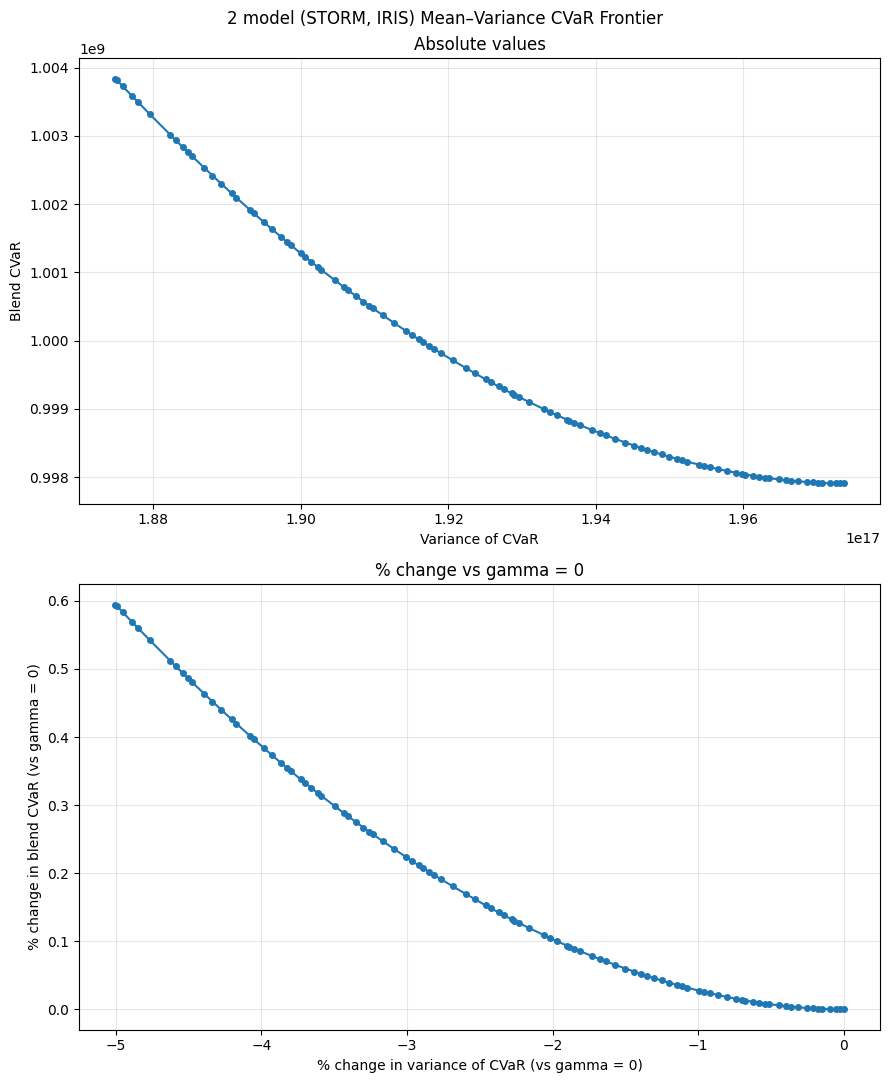

In [ ]:
rv_array = get_TC_model_array(["STORM", "IRIS"], tc_losses)
weights = np.array([1/2, 1/2])

PREMIUM_PRINCIPLE = 'ev'  
ev_frontier_df = generate_mean_variance_frontier(rv_array, weights, loading=4, alpha=0.05, n_points=100)
plot_frontier(ev_frontier_df, pct="both", title="2 model (STORM, IRIS) Mean–Variance CVaR Frontier")


In [16]:
ev_frontier_df


,gamma,optimal_deductible,blend_CVaR,variance_CVaR,per_model_CVaR,effective_weight_factors,effective_weights
0,0.000000e+00,13920.184010,2.712821e+08,1.434440e+16,"[151513993.23598212, 391050196.352312]","[1.0, 1.0]","[0.5, 0.5]"
1,4.216903e-11,13894.636501,2.712821e+08,1.434440e+16,"[151513993.51393893, 391050196.07867455]","[0.9898989899222501, 1.0101010100777499]","[0.49494949496112506, 0.5050505050388749]"
2,8.433807e-11,13835.077486,2.712821e+08,1.434440e+16,"[151513994.16968372, 391050195.4413943]","[0.9797979799535514, 1.0202020200464486]","[0.4898989899767757, 0.5101010100232243]"
3,1.265071e-10,13814.511998,2.712821e+08,1.434440e+16,"[151513994.3982357, 391050195.2240171]","[0.9696969699867404, 1.0303030300132596]","[0.4848484849933702, 0.5151515150066298]"
4,1.686761e-10,13768.714566,2.712821e+08,1.434440e+16,"[151513994.9143728, 391050194.7403994]","[0.9595959601509552, 1.0404040398490448]","[0.4797979800754776, 0.5202020199245224]"
...,...,...,...,...,...,...,...
95,4.006058e-09,9880.450350,2.712821e+08,1.434439e+16,"[151514060.93730372, 391050172.32287896]","[0.04040440788277788, 1.959595592117222]","[0.02020220394138894, 0.979797796058611]"
96,4.048227e-09,9859.770262,2.712821e+08,1.434439e+16,"[151514061.41501376, 391050172.3139865]","[0.030303403619842628, 1.9696965963801576]","[0.015151701809921314, 0.9848482981900788]"
97,4.090396e-09,9820.039912,2.712821e+08,1.434439e+16,"[151514062.33278483, 391050172.3020673]","[0.02020240121035055, 1.979797598789649]","[0.010101200605175276, 0.9898987993948245]"
98,4.132565e-09,9771.272414,2.712821e+08,1.434439e+16,"[151514063.46846187, 391050172.2937768]","[0.010101399764782304, 1.9898986002352181]","[0.005050699882391152, 0.9949493001176091]"


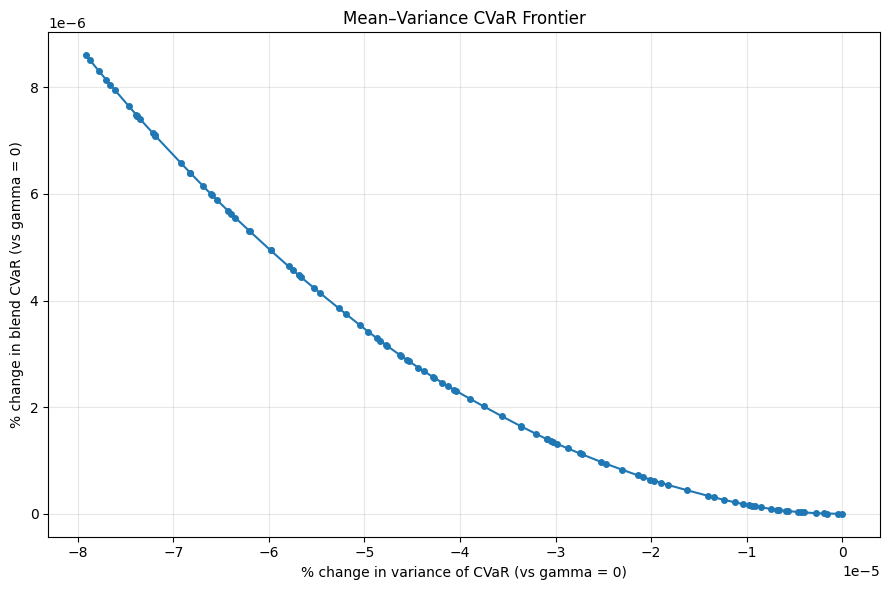

In [17]:
plot_frontier(ev_frontier_df, pct=True)


# Optimisation - frequency blend and blend of objective result confirmation

In [18]:
def blend(rv_array, weights):
    """
    Creates a single blended rv_discrete mixture model from an array of 
    discrete random variables and a corresponding set of weights.
    
    Parameters:
    -----------
    rv_array : list or array of scipy.stats.rv_discrete
        List of discrete random variable distributions.
    weights : list or array of float
        Mixing weights assigned to each distribution (must sum to 1).
        
    Returns:
    --------
    scipy.stats.rv_discrete
        The combined mixture distribution.
    """
    w = np.asarray(weights, dtype=float)
    w = w / np.sum(w)

    combined_xk = []
    combined_pk = []

    for rv, weight in zip(rv_array, w):
        combined_xk.extend(rv.xk)
        combined_pk.extend(rv.pk * weight)

    combined_xk = np.array(combined_xk)
    combined_pk = np.array(combined_pk)

    unique_xk, inverse_indices = np.unique(combined_xk, return_inverse=True)
    aggregated_pk = np.bincount(inverse_indices, weights=combined_pk)

    aggregated_pk /= np.sum(aggregated_pk)

    return stats.rv_discrete(name='blended_tc_impact', values=(unique_xk, aggregated_pk))


In [19]:
import numpy as np
from scipy.optimize import minimize_scalar

def optimize_deductible_single_model(rv_array, weights, loading, alpha):
    blended_dist = blend(rv_array, weights)

    xk = blended_dist.xk
    pk = blended_dist.pk

    def objective_function(deductible):
        d = max(0.0, float(deductible))
        
        premium = calc_stop_loss_premium(blended_dist, d, loading)
        
        total_risk_xk = np.minimum(xk, d) + premium
        
        unique_risk_xk, inverse_indices = np.unique(total_risk_xk, return_inverse=True)
        aggregated_pk = np.bincount(inverse_indices, weights=pk)
        
        tx_dist = stats.rv_discrete(name='total_risk', values=(unique_risk_xk, aggregated_pk))

        return calc_CVaR(tx_dist, alpha)

        
    max_possible_loss = float(np.max(xk))
    
    # Single-variable bounded optimization
    opt_result = minimize_scalar(
        objective_function, 
        bounds=(0.0, max_possible_loss), 
        method='bounded'
    )

    optimal_d = opt_result.x
    min_cvar = opt_result.fun

    return {
        'optimal_deductible': optimal_d,
        'min_cvar': min_cvar,
        'opt_result': opt_result
    }


In [20]:
rv_array = get_TC_model_array(["STORM", "CHAZ", "IRIS"], tc_losses)

# 2. Equal model weights
weights = [1/3, 1/3, 1/3]

# 3. Run optimal deductible search
result = optimize_deductible_single_model(
    rv_array=rv_array, 
    weights=weights, 
    loading=0.2, 
    alpha=0.05
)

print(result)
# 4. Display results
print(f"Optimal Deductible (d*): {result['optimal_deductible']:,.2f}")
print(f"Minimum Insurer CVaR_0.05: {result['min_cvar']:,.2f}")


{'optimal_deductible': np.float64(1262.1505164515024), 'min_cvar': np.float64(427129205.77695185), 'opt_result':  message: Solution found.
 success: True
  status: 0
     fun: 427129205.77695185
       x: 1262.1505164515024
     nit: 66
    nfev: 66}
Optimal Deductible (d*): 1,262.15
Minimum Insurer CVaR_0.05: 427,129,205.78


In [21]:
rv_array = get_TC_model_array(["STORM", "CHAZ", "IRIS"], tc_losses)

# 2. Equal model weights
weights = [1/3, 1/3, 1/3]

blended = blend(rv_array, weights)
loading=0.2
alpha=0.05
target_cdf = 1 - (1.0 / (1.0 + loading))

# 2. Get exact deductible directly via inverse CDF
optimal_d = float(blended.ppf(target_cdf))

print(f"Target CDF Threshold: {target_cdf:.6f}")
print(f"Direct Optimal Deductible d*: {optimal_d:,.2f}")


Target CDF Threshold: 0.166667
Direct Optimal Deductible d*: 1,262.15


In [22]:
import numpy as np
from scipy.optimize import minimize_scalar

def optimize_deductible_multiple_models(rv_array, weights, loading, alpha):

    n_models = len(rv_array)

    def single_model_objective(deductible, rv_array, i):
        model_dist = rv_array[i]
        d = max(0.0, float(deductible))

        xk = model_dist.xk
        pk = model_dist.pk

        premium = calc_stop_loss_premium(model_dist, d, loading)
        
        total_risk_xk = np.minimum(xk, d) + premium
        
        unique_risk_xk, inverse_indices = np.unique(total_risk_xk, return_inverse=True)
        aggregated_pk = np.bincount(inverse_indices, weights=pk)
        
        tx_dist = stats.rv_discrete(name='total_risk', values=(unique_risk_xk, aggregated_pk))

        return calc_CVaR(tx_dist, alpha)
        

    def objective_function(deductible):
        total_objective = 0.0
        for i in range(n_models):
            cvar_i = single_model_objective(deductible, rv_array, i)
            total_objective += weights[i] * cvar_i
        return total_objective

        
    max_possible_loss = float(max(np.max(model.xk) for model in rv_array))
    
    # Single-variable bounded optimization
    opt_result = minimize_scalar(
        objective_function, 
        bounds=(0.0, max_possible_loss), 
        method='bounded'
    )

    optimal_d = opt_result.x
    min_cvar = opt_result.fun

    return {
        'optimal_deductible': optimal_d,
        'min_cvar': min_cvar,
        'opt_result': opt_result
    }


In [23]:
rv_array = get_TC_model_array(["STORM", "CHAZ", "IRIS"], tc_losses)

# 2. Equal model weights
weights = [1/3, 1/3, 1/3]

# 3. Run optimal deductible search
result = optimize_deductible_multiple_models(
    rv_array=rv_array, 
    weights=weights, 
    loading=0.2, 
    alpha=0.05
)

print(result)

print(f"Optimal Deductible (d*): {result['optimal_deductible']:,.2f}")
print(f"Minimum Insurer CVaR_0.05: {result['min_cvar']:,.2f}")


{'optimal_deductible': np.float64(1262.1463854541114), 'min_cvar': np.float64(427129205.7769518), 'opt_result':  message: Solution found.
 success: True
  status: 0
     fun: 427129205.7769518
       x: 1262.1463854541114
     nit: 66
    nfev: 66}
Optimal Deductible (d*): 1,262.15
Minimum Insurer CVaR_0.05: 427,129,205.78
